**B?n holdout ?? ??i chi?u.** K?t qu? ch?y ?? 5 fold n?m trong [Lab02_5Fold_CV.ipynb](Lab02_5Fold_CV.ipynb) v? [BAO_CAO_CV.md](BAO_CAO_CV.md).

# Lab02 — Phân tích cảm xúc theo khía cạnh bằng Deep Learning

**Học phần:** Sentiment Analysis · **Nguồn bài tập:** Chapter 3, trang 21.

**Dữ liệu:** dùng nguyên `restaurant_aspect_train.csv` và `restaurant_aspect_test.csv` đã chuẩn hóa ở bài trước.
**Đơn vị dự đoán:** cặp *(câu, aspect_term)*. Không gộp nhãn để phân loại cả câu.

Bài làm gồm baseline ML; CNN/BiLSTM-Attention/hybrid; BERT embedding;
augmentation trên train; ensemble soft voting; Accuracy, Precision, Recall, F1, ROC-AUC;
confusion matrix và phân tích lỗi. Báo cáo hoàn chỉnh: [BAO_CAO.md](BAO_CAO.md).

Notebook đã lưu kết quả thực thi. Chọn kernel Python có dependencies trong `requirements.txt`.
Đặt `RUN_TRAINING = True` ở phần 7 nếu muốn huấn luyện lại toàn bộ.

## 1. Khởi tạo môi trường

In [1]:
from pathlib import Path
import os, sys, json, inspect
os.environ.setdefault('USE_TF', '0')
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Markdown, Image, Code

ROOT = Path.cwd()
if not (ROOT / 'run_experiment.py').exists():
    ROOT = ROOT / 'Lab02'
assert (ROOT / 'run_experiment.py').exists(), 'Mở notebook tại thư mục Lab02 hoặc thư mục cha.'
sys.path.insert(0, str(ROOT))
from data_utils import read_aspect_csv, LABELS, augment_train
from networks import SentimentNet
from run_experiment import Config, run, train_baselines, choose_ensemble
print('Thư mục:', ROOT)
print('PyTorch:', torch.__version__)
print('Thiết bị:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

D:\miniconda3\envs\py310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Thư mục: D:\Dai Hoc 0\Nam 4\HK1\Chuyen de 3\Bai Tap\Lab02
PyTorch: 2.11.0+cu130
Thiết bị: NVIDIA GeForce RTX 3060 Laptop GPU


## 2. Dữ liệu aspect-level có sẵn

Mỗi dòng giữ `text`, `aspect_term`, `polarity` và vị trí `from/to`. Một câu có thể xuất hiện
nhiều lần với các khía cạnh/nhãn khác nhau. Ba lớp: negative, neutral, positive.
Các CSV nguồn đã loại conflict. Hai file nguồn trong Lab02 là bản sao nguyên byte từ bài trước.

In [2]:
raw_train = pd.read_csv(ROOT / 'data/restaurant_aspect_train.csv')
raw_test = pd.read_csv(ROOT / 'data/restaurant_aspect_test.csv')
print('Train gốc:', raw_train.shape, '| Test gốc:', raw_test.shape)
display(raw_train[['sentence_id', 'text', 'aspect_term', 'polarity']].head())
display(pd.DataFrame({'train': raw_train.polarity.value_counts(),
                      'test': raw_test.polarity.value_counts()}).reindex(LABELS))
mixed = raw_train.groupby('text').polarity.nunique()
example = mixed[mixed > 1].index[0]
display(raw_train.loc[raw_train.text == example, ['text', 'aspect_term', 'polarity']])

Train gốc: (3602, 8) | Test gốc: (1120, 8)


,sentence_id,text,aspect_term,polarity
0,3121,But the staff was so horrible to us.,staff,negative
1,2777,"To be completely fair, the only redeeming fact...",food,positive
2,1634,"The food is uniformly exceptional, with a very...",food,positive
3,1634,"The food is uniformly exceptional, with a very...",kitchen,positive
4,1634,"The food is uniformly exceptional, with a very...",menu,neutral


,train,test
polarity,,
negative,805,196
neutral,633,196
positive,2164,728


,text,aspect_term,polarity
1717,(Always ask the bartender for the SEASONAL bee...,SEASONAL beer,positive
1718,(Always ask the bartender for the SEASONAL bee...,bartender,neutral


## 3. Chia train/validation và tránh rò rỉ

Giữ nguyên 1.120 mẫu test. Loại một mẫu train có câu trùng test.
Lấy fold đầu của StratifiedGroupKFold 5 folds, seed 42. Group theo câu để các khía cạnh
của cùng câu không nằm ở cả train và validation; **nhãn vẫn theo từng khía cạnh**.
Đây là một holdout, chưa phải trung bình nhiều fold. Không dùng test để chọn mô hình.

In [3]:
train = pd.read_csv(ROOT / 'data/train.csv')
validation = pd.read_csv(ROOT / 'data/validation.csv')
test = pd.read_csv(ROOT / 'data/test.csv')
for a, b in [(train, validation), (train, test), (validation, test)]:
    assert set(a.group).isdisjoint(b.group)
audit = json.loads((ROOT / 'results/data_audit.json').read_text(encoding='utf-8'))
display(pd.DataFrame(audit['splits']).T)
print('Mẫu train loại do trùng test:', audit['removed_train_overlap'])
assert test[['text', 'aspect', 'label']].values.tolist() == raw_test[['text', 'aspect_term', 'polarity']].values.tolist()

,rows,sentences,classes
train,2850,1567,"{'positive': 1723, 'negative': 626, 'neutral':..."
validation,751,408,"{'positive': 440, 'negative': 179, 'neutral': ..."
test,1120,600,"{'positive': 728, 'neutral': 196, 'negative': ..."


Mẫu train loại do trùng test: 1


## 4. Baseline Machine Learning

TF-IDF unigram/bigram, có aspect và cửa sổ ngữ cảnh. Dùng Majority, Multinomial NB,
Logistic Regression và calibrated Linear SVM. Huấn luyện lại trên cùng train và đánh giá cùng test với DL.
SVM hiệu chỉnh xác suất bằng 3-fold theo nhóm trong train; vectorizer cũng fit trong từng fold.
Giữ từ phủ định, không xóa stopwords. Mã chạy baseline:

In [4]:
display(Code(inspect.getsource(train_baselines), language='python'))

def train_baselines(train, val, test, config):
    def vectorizer():
        return TfidfVectorizer(lowercase=True, strip_accents="unicode", ngram_range=(1, 2),
                               min_df=2, sublinear_tf=True, max_features=30000)
    cv = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=config.seed)
              .split(train, train.y, train.group))
    estimators = {
        "Majority": make_pipeline(vectorizer(), DummyClassifier(strategy="prior")),
        "TFIDF_NaiveBayes": make_pipeline(vectorizer(), MultinomialNB(alpha=1.0)),
        "TFIDF_LogisticRegression": make_pipeline(vectorizer(), LogisticRegression(
            C=2.0, max_iter=1500, class_weight="balanced", random_state=config.seed)),
        "TFIDF_LinearSVM": CalibratedClassifierCV(
            make_pipeline(vectorizer(), LinearSVC(C=1.0, class_weight="balanced",
                                                  random_state=config.seed)), cv=cv),
    }
    xtrain, xval, xtest = [baseline_text(df) for df in (train, val, test)]
    vp, tp, durations = {}, {}, {}
    for name, estimator in estimators.items():
        start = time.perf_counter()
        estimator.fit(xtrain, train.y)
        vp[name] = estimator.predict_proba(xval)
        tp[name] = estimator.predict_proba(xtest)
        assert list(estimator.classes_) == [0, 1, 2]
        durations[name] = time.perf_counter()-start
        joblib.dump(estimator, ROOT / "models" / f"{name}.joblib")
        print(f"{name}: validation macro F1={metrics(val.y, vp[name])['f1_macro']:.4f}", flush=True)
    return vp, tp, durations

## 5. Feature Engineering: BERT

Dùng pretrained `bert-base-uncased`, đóng băng encoder và lấy vector token tầng cuối (768 chiều).
Chuỗi vào là `[CLS] aspect [SEP] review [SEP]`. Chỉ cắt review khi vượt 96 token, giữ aspect.
Mạng phía sau học phép chiếu 768 → 96 chiều. Đây là feature extraction, không fine-tune BERT.

Không stemming hoặc loại dấu câu trước BERT. Embedding ngẫu nhiên dùng cùng WordPiece là mốc ablation.
[Model card BERT](https://huggingface.co/google-bert/bert-base-uncased).

In [5]:
features_info = json.loads((ROOT / 'results/bert_features.json').read_text(encoding='utf-8'))
print('BERT:', features_info['model'], '| revision:', features_info['revision'])
print('Cấu trúc cặp:', features_info['pair_format'])
display(pd.DataFrame(features_info['splits']).T)
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased', local_files_only=True)
sample = tokenizer('service', 'The food was excellent but the service was slow.')
print(tokenizer.convert_ids_to_tokens(sample['input_ids']))

BERT: bert-base-uncased | revision: 86b5e0934494bd15c9632b12f734a8a67f723594
Cấu trúc cặp: [CLS] aspect [SEP] review [SEP]


,rows,truncated,seconds,fingerprint
train,2850,0,9.320789,171b7f578950146ba68a
validation,751,0,2.363117,fca33a6c7f470d91667a
test,1120,0,4.958788,af81a74c7cf022f3e413
augmented,4027,0,17.474544,05d1b9375582f098d2df


['[CLS]', 'service', '[SEP]', 'the', 'food', 'was', 'excellent', 'but', 'the', 'service', 'was', 'slow', '.', '[SEP]']


## 6. Data Augmentation

Sinh biến thể **chỉ từ train**: thay một từ bằng đồng nghĩa từ từ điển cố định;
hoặc xóa ngẫu nhiên một từ trong `really`, `very`, `quite`, `just` nếu có.
Giữ aspect, cập nhật offset và không xóa từ phủ định; loại bản trùng lặp/đụng validation hoặc test.
Đây là heuristic, không bảo đảm giữ trọn sắc thái. Thí nghiệm có/không augmentation sẽ kiểm chứng hiệu quả.

In [6]:
augmented = pd.read_csv(ROOT / 'data/train_augmented.csv')
display(augmented.augmentation.value_counts().rename('Số mẫu').to_frame())
generated = augmented[augmented.augmentation != 'original']
examples = generated.merge(train[['row_id', 'text']], left_on='parent_id', right_on='row_id', suffixes=('_aug', '_original'))
display(examples[['text_original', 'text_aug', 'aspect', 'label', 'augmentation']].head(8))
assert set(generated.group).isdisjoint(set(validation.group) | set(test.group))
assert all(r.text[r.start:r.end] == r.aspect for r in augmented.itertuples())

,Số mẫu
augmentation,
original,2850
synonym,786
restricted_deletion,391


,text_original,text_aug,aspect,label,augmentation
0,"The food is uniformly exceptional, with a very...","The food is uniformly exceptional, with a cap...",food,positive,restricted_deletion
1,"The food is uniformly exceptional, with a very...","The food is uniformly exceptional, with a cap...",kitchen,positive,restricted_deletion
2,"The food is uniformly exceptional, with a very...","The food is uniformly exceptional, with a cap...",menu,neutral,restricted_deletion
3,Nevertheless the food itself is pretty good.,Nevertheless the food itself is pretty nice.,food,positive,synonym
4,The design and atmosphere is just as good.,The design and atmosphere is just as nice.,design,positive,synonym
5,The design and atmosphere is just as good.,The design and atmosphere is as good.,design,positive,restricted_deletion
6,The design and atmosphere is just as good.,The design and atmosphere is just as nice.,atmosphere,positive,synonym
7,The design and atmosphere is just as good.,The design and atmosphere is as good.,atmosphere,positive,restricted_deletion


## 7. Kiến trúc và huấn luyện

```text
(review, aspect) → WordPiece → BERT đóng băng → Linear(768, 96)
                                        ├→ CNN kernels 3/5/7 → masked max pool ┐
                                        └→ BiLSTM → masked attention         ├→ concat → dropout → 3 logits
                                                                             ┘
```

CNN và BiLSTM-Attention cũng được huấn luyện độc lập. `Random_Hybrid` thay BERT bằng
embedding khởi tạo ngẫu nhiên. Hybrid là một mạng ghép đặc trưng; soft voting ở phần sau mới là ensemble các mạng.

AdamW lr=0.001, batch=64, tối đa 20 epochs, patience=4 theo validation macro F1;
weighted cross-entropy từ train gốc, gradient clipping 1.0. Khôi phục checkpoint validation tốt nhất.
Mask và packed sequences ngăn padding tác động đến kết quả.

In [7]:
display(Code(inspect.getsource(SentimentNet), language='python'))
print('Cấu hình đã thực chạy:')
display(json.loads((ROOT / 'results/config.json').read_text()))

class SentimentNet(nn.Module):
    def __init__(self, architecture="hybrid", pretrained=True, vocab_size=30522,
                 feature_dim=768, hidden=64, projection=96, dropout=0.35):
        super().__init__()
        self.architecture = architecture
        self.pretrained = pretrained
        self.embedding = (nn.Linear(feature_dim, projection) if pretrained else
                          nn.Embedding(vocab_size, projection, padding_idx=0))
        self.input_dropout = nn.Dropout(dropout)
        out_dim = 0
        if architecture in {"cnn", "hybrid"}:
            self.convs = nn.ModuleList([nn.Conv1d(projection, hidden, k, padding=k//2)
                                        for k in (3, 5, 7)])
            out_dim += hidden * 3
        if architecture in {"bilstm", "hybrid"}:
            self.lstm = nn.LSTM(projection, hidden, batch_first=True, bidirectional=True)
            self.attention = nn.Sequential(nn.Linear(hidden*2, hidden), nn.Tanh(),
                                           nn.Linear(hidden, 1, bias=False))
            out_dim += hidden * 2
        if not out_dim:
            raise ValueError(architecture)
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(out_dim, 3))

    def forward(self, inputs, mask):
        mask = mask.bool()
        features = self.embedding(inputs.float() if self.pretrained else inputs.long())
        features = self.input_dropout(features) * mask.unsqueeze(-1)
        branches = []
        if self.architecture in {"cnn", "hybrid"}:
            cnn = features.transpose(1, 2)
            branches += [torch.relu(conv(cnn)).masked_fill(~mask.unsqueeze(1), -1e4)
                         .amax(dim=2) for conv in self.convs]
        if self.architecture in {"bilstm", "hybrid"}:
            packed = pack_padded_sequence(features, mask.sum(1).cpu(),
                                           batch_first=True, enforce_sorted=False)
            packed_out, _ = self.lstm(packed)
            seq, _ = pad_packed_sequence(packed_out, batch_first=True,
                                          total_length=features.size(1))
            scores = self.attention(seq).squeeze(-1).masked_fill(~mask, -1e4)
            weights = torch.softmax(scores, dim=1)
            branches.append((seq * weights.unsqueeze(-1)).sum(1))
        return self.classifier(torch.cat(branches, dim=-1))

Cấu hình đã thực chạy:


{'seed': 42,
 'epochs': 20,
 'patience': 4,
 'batch_size': 64,
 'feature_batch_size': 24,
 'max_length': 96,
 'learning_rate': 0.001,
 'bert_model': 'bert-base-uncased',
 'local_files_only': True,
 'device': 'auto',
 'threads': 4}

In [8]:
RUN_TRAINING = False  # Đổi True để huấn luyện lại và ghi đè kết quả.
if RUN_TRAINING:
    run(Config())  # Máy mới: Config(local_files_only=False) để tải BERT.
else:
    assert (ROOT / 'results/metrics_test.csv').exists(), 'Chưa có kết quả: đặt RUN_TRAINING=True.'
    print('Đọc kết quả đã chạy; không huấn luyện lại trong lần mở notebook này.')

Đọc kết quả đã chạy; không huấn luyện lại trong lần mở notebook này.


## 8. Ensemble

Soft voting kết hợp xác suất BERT-CNN, BERT-BiLSTM-Attention và BERT-Hybrid-Augmented:
`P(c|x) = Σ w_m P_m(c|x)`. Tất cả trọng số dương và tổng bằng 1.
Chọn trọng số từ 27 tổ hợp cố định theo validation macro F1; test chỉ dùng báo cáo cuối.

In [9]:
ensemble = json.loads((ROOT / 'models/ensemble.json').read_text())
display(pd.DataFrame({'Mô hình': ensemble['members'], 'Trọng số': ensemble['weights']}))
print('Validation macro F1:', ensemble['validation_f1_macro'])
display(Code(inspect.getsource(choose_ensemble), language='python'))

,Mô hình,Trọng số
0,BERT_CNN,0.250
1,BERT_BiLSTM_Attention,0.375
2,BERT_Hybrid_Augmented,0.375


Validation macro F1: 0.6599035319449162


def choose_ensemble(validation_predictions, y):
    members = ["BERT_CNN", "BERT_BiLSTM_Attention", "BERT_Hybrid_Augmented"]
    stacked = np.stack([validation_predictions[n] for n in members])
    best_score, best_weights = -1.0, None
    # 27 predeclared positive-weight candidates, selected ONLY by validation F1.
    for candidate in itertools.product((1, 2, 3), repeat=3):
        weights = np.array(candidate, dtype=float)/sum(candidate)
        score = f1_score(y, np.einsum("m,mnc->nc", weights, stacked).argmax(-1), average="macro")
        if score > best_score+1e-8:
            best_score, best_weights = score, weights
    return dict(members=members, weights=best_weights.tolist(), validation_f1_macro=best_score,
                selection="27 fixed candidates; validation macro F1 only")

## 9. Đánh giá định lượng

Accuracy = số mẫu đúng / tổng mẫu. Precision = TP/(TP+FP); Recall = TP/(TP+FN);
F1 = 2PR/(P+R). Macro lấy trung bình đều ba lớp, weighted F1 theo support.
ROC dùng **xác suất từng lớp** theo one-vs-rest, AUC lấy macro.
Chọn mô hình bằng validation macro F1 vì positive chiếm đa số; không chọn theo test.

,model,validation_f1,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr_macro
9,SoftVoting_Ensemble,0.6599,0.7652,0.6654,0.6869,0.6727,0.7648,0.8869
7,BERT_Hybrid,0.6542,0.7839,0.6891,0.6816,0.6833,0.7776,0.8686
8,BERT_Hybrid_Augmented,0.6450,0.7589,0.6641,0.6924,0.6712,0.7589,0.8821
5,BERT_CNN,0.6383,0.7750,0.6884,0.6584,0.6716,0.7688,0.8626
6,BERT_BiLSTM_Attention,0.6282,0.7339,0.6494,0.6995,0.6669,0.7462,0.8751
2,TFIDF_LogisticRegression,0.5745,0.7348,0.6282,0.6266,0.6226,0.7291,0.8503
3,TFIDF_LinearSVM,0.5365,0.7304,0.6440,0.5460,0.5568,0.6926,0.8440
4,Random_Hybrid,0.5172,0.6830,0.5546,0.5379,0.5402,0.6697,0.7702
1,TFIDF_NaiveBayes,0.2865,0.6580,0.7647,0.3486,0.2938,0.5311,0.8410
0,Majority,0.2463,0.6500,0.2167,0.3333,0.2626,0.5121,0.5000


**Mô hình được chọn theo validation:** `SoftVoting_Ensemble`

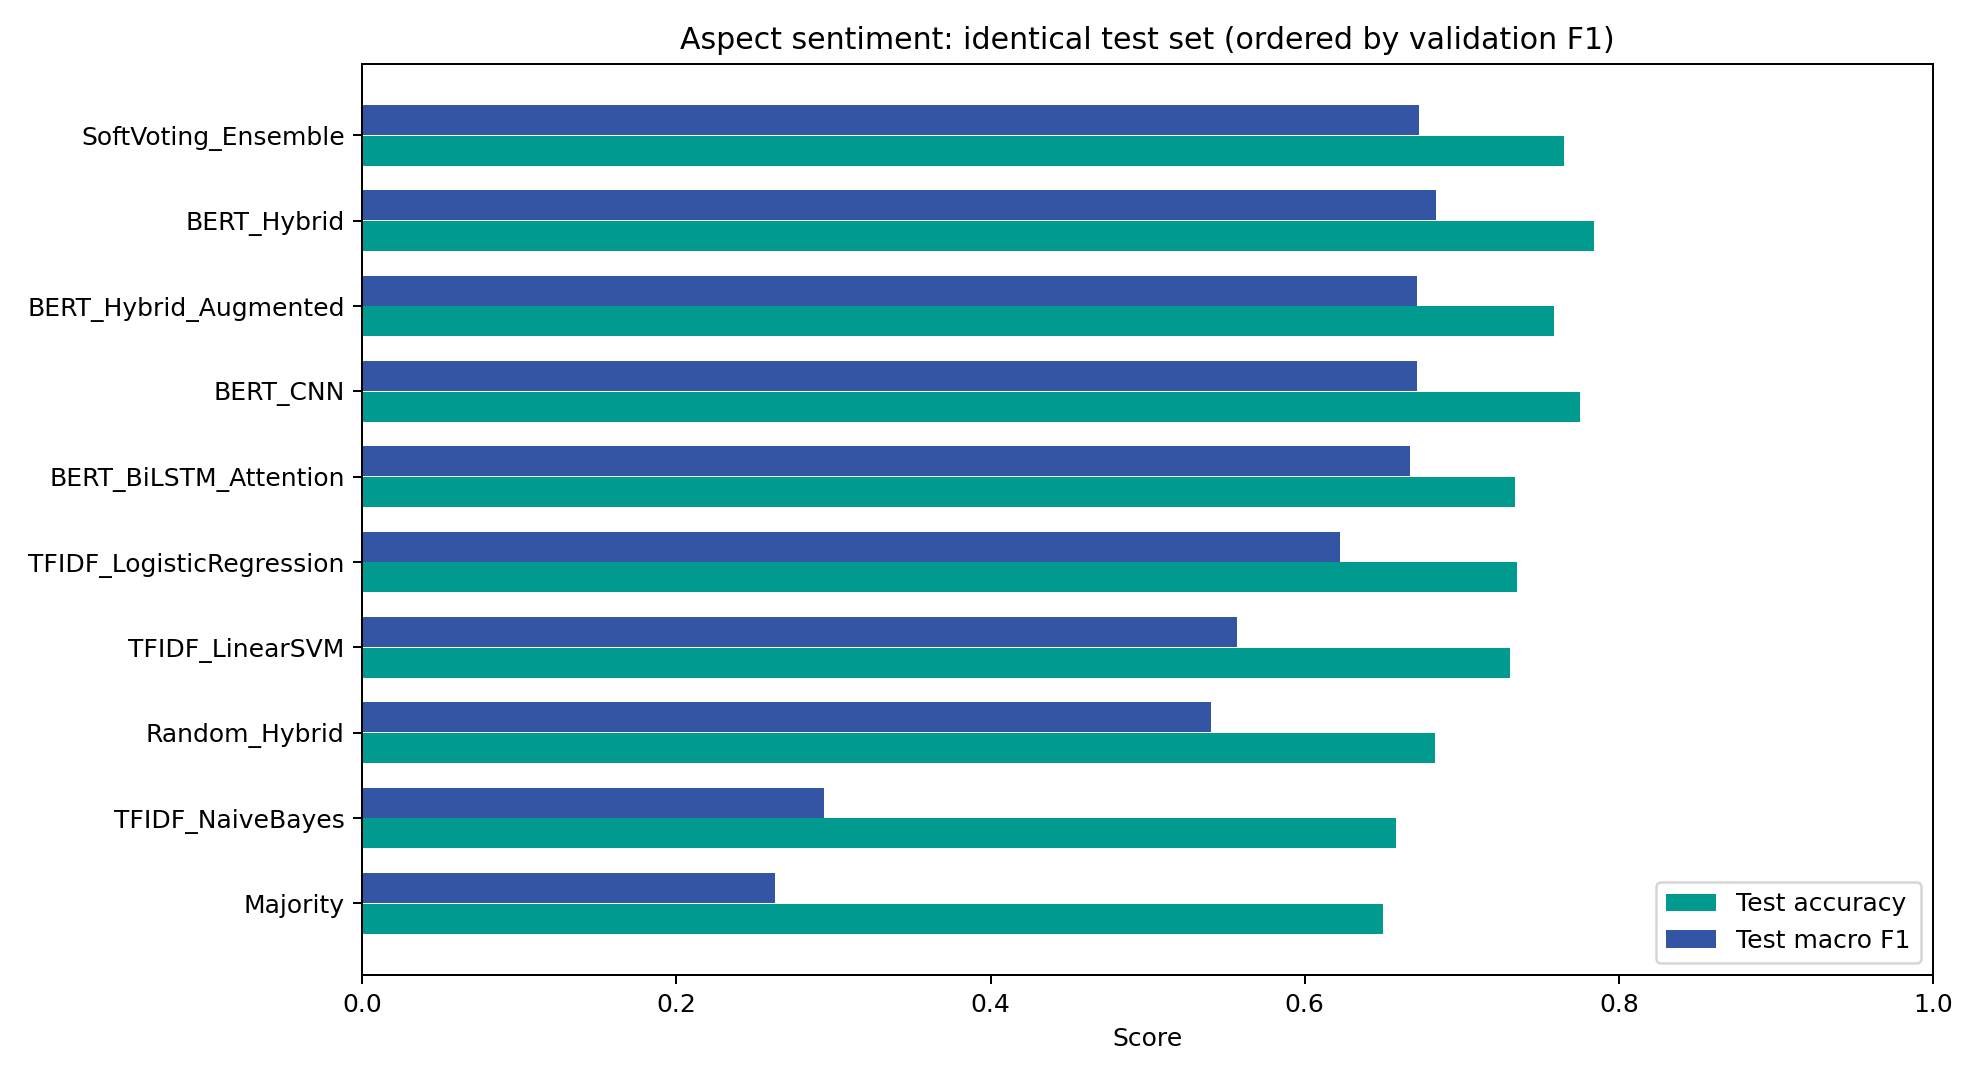

In [10]:
test_metrics = pd.read_csv(ROOT / 'results/metrics_test.csv')
val_metrics = pd.read_csv(ROOT / 'results/metrics_validation.csv')
comparison = val_metrics[['model', 'f1_macro']].rename(columns={'f1_macro': 'validation_f1'}).merge(test_metrics, on='model')
display(comparison.sort_values('validation_f1', ascending=False).round(4))
selected = json.loads((ROOT / 'models/selected_model.json').read_text())['model']
display(Markdown(f'**Mô hình được chọn theo validation:** `{selected}`'))
display(Image(filename=str(ROOT / 'results/model_comparison.png')))

## 10. Ablation: embedding, augmentation và ensemble

,Thay đổi,Trước,Sau,Delta accuracy (điểm %),Delta macro F1 (điểm %)
0,BERT embedding,Random_Hybrid,BERT_Hybrid,10.09,14.31
1,Augmentation,BERT_Hybrid,BERT_Hybrid_Augmented,-2.50,-1.21
2,Ensemble vs hybrid augmented,BERT_Hybrid_Augmented,SoftVoting_Ensemble,0.62,0.15


Số âm là giảm chất lượng. Không khẳng định augmentation/ensemble luôn cải thiện. Một seed và một holdout chưa đủ để kết luận ý nghĩa thống kê.

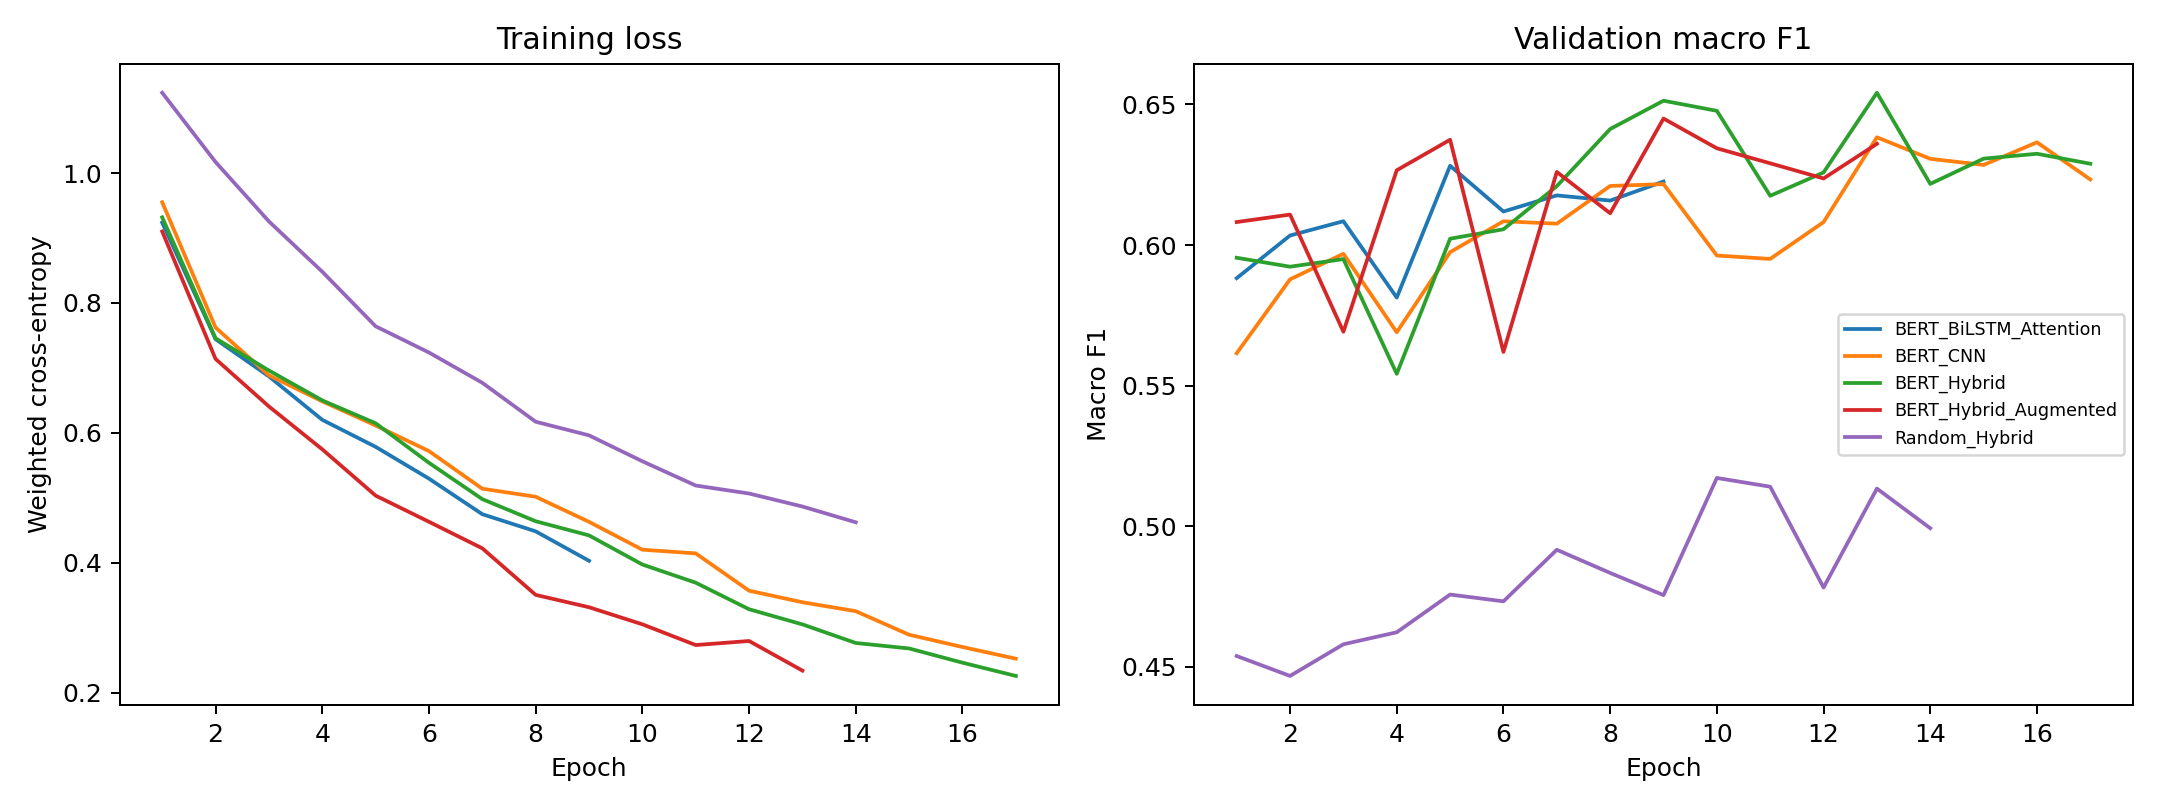

In [11]:
scores = test_metrics.set_index('model')
rows = []
for factor, before, after in [
    ('BERT embedding', 'Random_Hybrid', 'BERT_Hybrid'),
    ('Augmentation', 'BERT_Hybrid', 'BERT_Hybrid_Augmented'),
    ('Ensemble vs hybrid augmented', 'BERT_Hybrid_Augmented', 'SoftVoting_Ensemble')]:
    rows.append({'Thay đổi': factor, 'Trước': before, 'Sau': after,
                 'Delta accuracy (điểm %)': 100*(scores.loc[after, 'accuracy']-scores.loc[before, 'accuracy']),
                 'Delta macro F1 (điểm %)': 100*(scores.loc[after, 'f1_macro']-scores.loc[before, 'f1_macro'])})
display(pd.DataFrame(rows).round(2))
display(Markdown('Số âm là giảm chất lượng. Không khẳng định augmentation/ensemble luôn cải thiện. '
                 'Một seed và một holdout chưa đủ để kết luận ý nghĩa thống kê.'))
display(Image(filename=str(ROOT / 'results/learning_curves.png')))

## 11. Confusion matrix, ROC và phân tích lỗi

,precision,recall,f1-score,support
negative,0.6230,0.7755,0.6909,196.0
neutral,0.4913,0.4337,0.4607,196.0
positive,0.8819,0.8516,0.8665,728.0


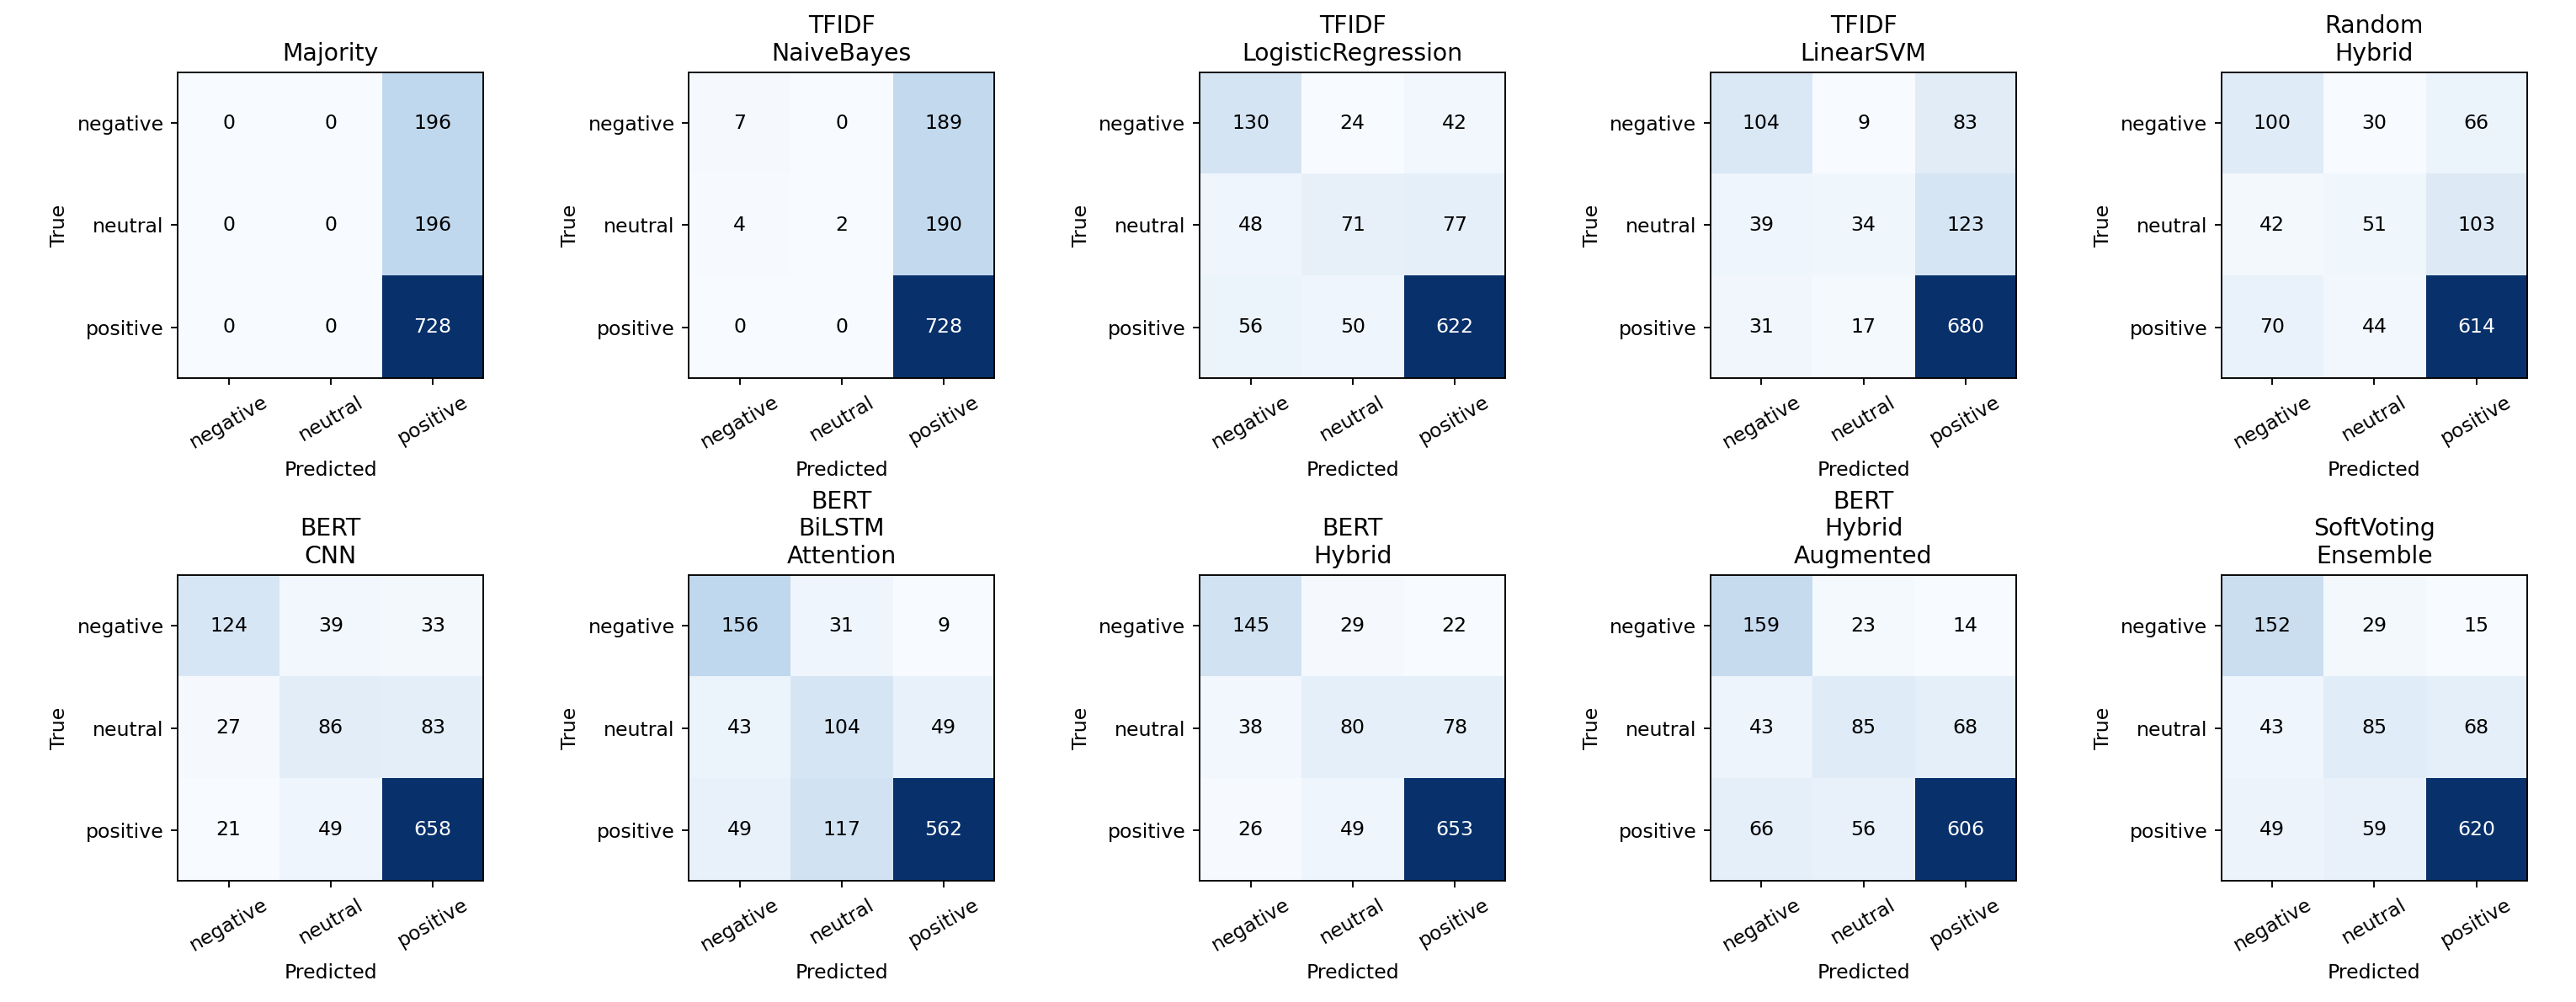

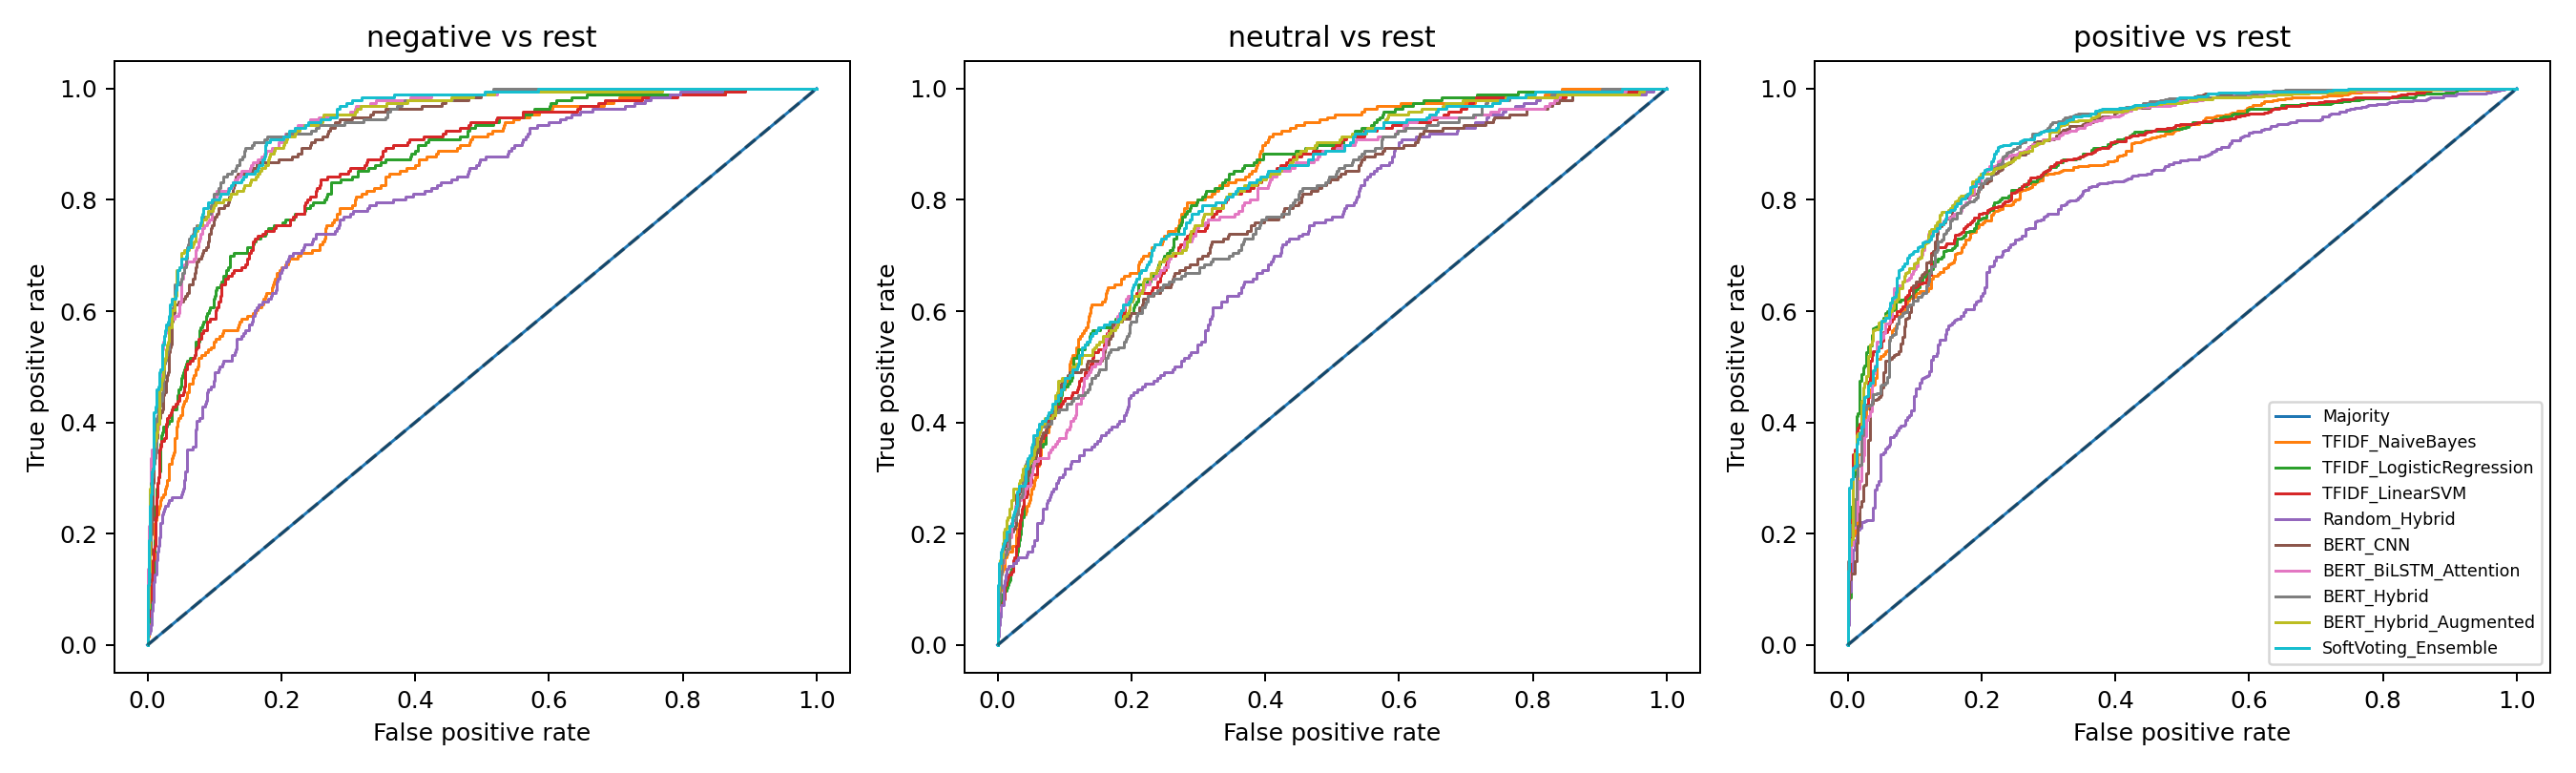

Số dự đoán sai: 263 / 1120


,text,aspect,label,predicted
0,Did I mention that the coffee is OUTSTANDING?,coffee,positive,neutral
1,"Certainly not the best sushi in New York, howe...",place,positive,negative
2,"I trust the people at Go Sushi, it never disap...",people,positive,neutral
3,"While there's a decent menu, it shouldn't take...",menu,positive,neutral
4,The sangria's - watered down.,sangria,negative,positive
5,Anytime and everytime I find myself in the nei...,sushi,positive,neutral
6,Great food but the service was dreadful!,food,positive,negative
7,The portions of the food that came out were me...,portions of the food,neutral,negative
8,We enjoyed ourselves thoroughly and will be go...,desserts,positive,neutral
9,THE LASAGNA WAS PROBABLY THE BEST I HAVE TASTED.,LASAGNA,positive,neutral


Số lỗi
label    predicted        
neutral  positive       68
positive neutral        59
         negative       49
neutral  negative       43
negative neutral        29
         positive       15

In [12]:
report = json.loads((ROOT / f'results/classification_report_{selected}.json').read_text())
display(pd.DataFrame({label: report[label] for label in LABELS}).T.round(4))
display(Image(filename=str(ROOT / 'results/confusion_matrices.png')))
display(Image(filename=str(ROOT / 'results/roc_ovr.png')))
errors = pd.read_csv(ROOT / f'results/errors_{selected}.csv')
print('Số dự đoán sai:', len(errors), '/', len(test))
display(errors[['text', 'aspect', 'label', 'predicted']].head(10))
display(errors.groupby(['label', 'predicted']).size().rename('Số lỗi').sort_values(ascending=False).to_frame())

Kiểm tra thủ công lỗi ở các câu có nhiều aspect với cảm xúc đối lập, phủ định,
ý kiến ngầm hoặc sắc thái neutral. Không tự gán nguyên nhân lỗi nếu chưa đọc từng câu.
Giới hạn: BERT đóng băng, một seed, augmentation thủ công; đầu vào chưa đánh dấu vị trí aspect
nên có thể nhầm khi cùng tên aspect xuất hiện nhiều lần. Chưa kiểm chứng khả năng chuyển miền.

**Hướng cải tiến:** nhiều seed, fine-tune BERT có target markers, kiểm tra biến thể tăng cường,
back translation và đánh giá trên miền khác. Đánh giá mọi lựa chọn bằng validation trước khi dùng test.

## 12. Nạp checkpoint để dự đoán một khía cạnh mới

In [13]:
from predict import predict
demo = predict('The food was excellent but the service was slow.', 'service')
display(demo)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  88%|████████▊ | 175/199 [00:00<00:00, 1738.92it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1779.61it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'text': 'The food was excellent but the service was slow.',
 'aspect': 'service',
 'model': 'SoftVoting_Ensemble',
 'label': 'negative',
 'probabilities': {'negative': 0.9508119225502014,
  'neutral': 0.023811932987882756,
  'positive': 0.025376136356499046}}

## 13. Kết luận và tài liệu

Các bảng trên là kết quả thực nghiệm, không phải số liệu kỳ vọng. Mọi phương pháp đều đánh giá
trên cùng 1.120 mẫu khía cạnh; test không tham gia huấn luyện, early stopping hay chọn trọng số ensemble.

- [Báo cáo đầy đủ và nhận xét từ số liệu](BAO_CAO.md).
- [Cách chạy và cấu trúc bài làm](README.md).
- Slide Chapter 3, trang 11–21, đặc biệt Exercise trang 21.
- [SemEval-2014 Task 4](https://alt.qcri.org/semeval2014/task4/index.php).
- [BERT-base-uncased](https://huggingface.co/google-bert/bert-base-uncased).
- [PyTorch LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.modules.rnn.LSTM.html).
- [Scikit-learn grouped cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html).